# WDC-PAVE: Product Attribute Extraction with Small Language Models

**Question:** Does fine-tuning a small model improve category prediction and normalized attribute extraction?

Work top to bottom. Start with `RUN_TRAINING = False` to measure the pretrained baseline. Then change the configuration cell and rerun from the top. No helper files or separate training scripts.

**Rules:** Training uses `train`; model selection uses `validation`; `test` is for one final evaluation. The same prompts, decoding settings, and examples are used before and after training.

## 1. Environment

Use a **GPU runtime** in Colab (L4 preferred). Package versions are pinned so changing Colab defaults is less likely to break the notebook. Installing does not start training.

In [1]:
%pip -q install "transformers==4.57.1" "datasets==4.8.5" "peft==0.17.1" "accelerate==1.11.0" "bitsandbytes==0.48.2" sentencepiece matplotlib pandas

In [2]:
# Standard library
import json
import random
import time
from pathlib import Path
from pprint import pprint

# Data and visualization
import matplotlib.pyplot as plt
import pandas as pd
from datasets import load_dataset
from tqdm.auto import tqdm

# Models and training
import torch
from transformers import (
    AutoModelForCausalLM,
    AutoModelForSeq2SeqLM,
    AutoTokenizer,
    BitsAndBytesConfig,
    DataCollatorForSeq2Seq,
    Trainer,
    TrainingArguments,
)
from peft import LoraConfig, PeftModel, get_peft_model, prepare_model_for_kbit_training
from google.colab import drive

## 2. Experiment configuration

**Change settings here only.** Run names must be different when you want to keep two experiments. `full` is limited to FLAN-T5-base to avoid large GPU memory requirements. `qlora` is limited to decoder-only models.

In [18]:
# Model: "qwen3", "smollm2", or "flan-t5"
MODEL_NAME = "qwen3"
METHOD = "lora"              # "lora", "qlora", or "full" (FLAN-T5 only)
EXPERIMENT_NAME = "qwen3-lora-01"
RUN_TRAINING = True         # First run: False. Later change to True.
LOAD_CHECKPOINT_DIR = ""     # Optional saved final_model path; blank for a fresh run.
FINAL_TEST = False           # Change only after choosing the final model.

# Training
SEED = 42
EPOCHS = 1
LEARNING_RATE = 2e-4        # Try ~2e-5 for full fine-tuning.
BATCH_SIZE = 1
GRAD_ACCUM_STEPS = 8
LORA_R = 8
LORA_ALPHA = 16
LORA_DROPOUT = 0.05
OPTIMIZER = "adamw_torch"   # Or "paged_adamw_8bit" with bitsandbytes

# Token lengths and evaluation
MAX_SOURCE_TOKENS = 1024
MAX_TARGET_TOKENS = 512
EVAL_N = 24                 # Quick comparisons on the same fixed validation examples
N_SHOTS = 2  # 0 = schema zero-shot, 2 = schema two-shot

# Drive folder supplied for this project
DRIVE_DIR = "/content/drive/MyDrive/WDC-PAV-Finetuning"

MODEL_IDS = {
    "qwen3": "Qwen/Qwen3-1.7B",
    "smollm2": "HuggingFaceTB/SmolLM2-1.7B-Instruct",
    "flan-t5": "google/flan-t5-base",
}
assert MODEL_NAME in MODEL_IDS
assert METHOD in {"lora", "qlora", "full"}
assert METHOD != "full" or MODEL_NAME == "flan-t5", "Full training is supported here only for FLAN-T5."
assert METHOD != "qlora" or MODEL_NAME != "flan-t5", "Use LoRA or full fine-tuning for FLAN-T5."
assert not (RUN_TRAINING and LOAD_CHECKPOINT_DIR), "Train fresh or load a checkpoint, not both."
MODEL_ID = MODEL_IDS[MODEL_NAME]
IS_SEQ2SEQ = MODEL_NAME == "flan-t5"

In [4]:
drive.mount("/content/drive")
output_root = Path(DRIVE_DIR)
assert output_root.is_dir(), f"Drive folder not found at {output_root}. Check its location in My Drive."

run_dir = output_root / EXPERIMENT_NAME

# Prevent accidental reuse of an existing training experiment.
if RUN_TRAINING and run_dir.exists() and any(run_dir.iterdir()):
    raise FileExistsError(
        f"Experiment '{EXPERIMENT_NAME}' already contains files. "
        "Choose a new EXPERIMENT_NAME before training."
    )

run_dir.mkdir(parents=True, exist_ok=True)


random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

assert torch.cuda.is_available(), "Switch Colab to Runtime > Change runtime type > GPU."
DEVICE = "cuda"
DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
if IS_SEQ2SEQ and DTYPE == torch.float16:
    DTYPE = torch.float32  # T5 is often unstable in float16.

print("GPU:", torch.cuda.get_device_name(0))
print("Experiment:", EXPERIMENT_NAME, "| Model:", MODEL_ID, "| Method:", METHOD)
print("Output:", run_dir)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: NVIDIA L4
Experiment: qwen3-lora-01 | Model: Qwen/Qwen3-1.7B | Method: lora
Output: /content/drive/MyDrive/WDC-PAV-Finetuning/qwen3-lora-01


## 3. Load and inspect data

Loading the three JSONL files separately avoids the repository-level split-generation issue observed in this dataset. **Do not clean questionable labels silently**: label noise is part of the experiment's limitations.

In [5]:
base_url = "hf://datasets/siavashsaki/wdc-pave-ave"
data = {
    "train": load_dataset("json", data_files=f"{base_url}/train.jsonl", split="train"),
    "validation": load_dataset("json", data_files=f"{base_url}/val.jsonl", split="train"),
    "test": load_dataset("json", data_files=f"{base_url}/test.jsonl", split="train"),
}
categories = sorted(set(data["train"]["category"]))
print({split: len(records) for split, records in data.items()})
print(pd.Series(data["train"]["category"]).value_counts().to_string())
print("\nFirst record:", data["train"][0])

{'train': 994, 'validation': 142, 'test': 284}
Computers And Accessories    305
Home And Garden              250
Office Products              207
Jewelry                      175
Grocery And Gourmet Food      57

First record: {'id': 8068358, 'category': 'Home And Garden', 'input_title': 'Pneumatic Lift Lab Stools w/Back, Height-Adjustable, 17-22, Black w/Back by Safco SAF3430BL - OnTimeSupplies.com', 'input_description': 'Pneumatic lift adjusts to accommodate different workstation heights. Generously cushioned seat and adjustable back for added comfort. Long-wearing upholstery stands up to everyday wear-and-tear and easy to clean vinyl for easy maintenance. 360 swivel helps to support movement throughout the day, which may help support better circulation and ease pressure points.', 'gold_json': {'Product Type': 'Furniture, Storage, Racks and Fixtures', 'Color': 'Black', 'Length': None, 'Width': None, 'Height': '99.1', 'Depth': None, 'Manufacturer Stock Number': 'SAF3430BL', 'Retail UP

In [6]:
# Lightweight label audit (no edits to the provided labels)
for split, records in data.items():
    missing_text = sum(not (r["input_title"] or r["input_description"]) for r in records)
    strange_target = sum(not isinstance(r["gold_json"], dict) for r in records)
    unfamiliar_category = sum(r["category"] not in categories for r in records)
    print(split, {"missing_title_and_description": missing_text,
                  "non_dictionary_target": strange_target,
                  "unknown_category": unfamiliar_category})

train {'missing_title_and_description': 0, 'non_dictionary_target': 0, 'unknown_category': 0}
validation {'missing_title_and_description': 0, 'non_dictionary_target': 0, 'unknown_category': 0}
test {'missing_title_and_description': 0, 'non_dictionary_target': 0, 'unknown_category': 0}


## 4. Define the learning problem

**Input:** title and description (no category supplied). **Output:** JSON containing the category and that category's attributes. Some targets require unit conversions or multiple values; unsupported targets are a known source of label noise.

In [7]:
# Derive allowed attributes using training data only.
CATEGORY_SCHEMAS = {
    category: sorted({
        key
        for record in data["train"]
        if record["category"] == category
        for key in record["gold_json"]
    })
    for category in categories
}

SYSTEM_PROMPT = (
    "Classify the product and extract its attributes.\n"
    "Return only JSON with keys 'category' and 'attributes'.\n"
    "Use exactly the attribute names listed for the predicted category.\n"
    "Set missing attributes to null. Normalize values. Do not invent details.\n\n"
    "Allowed categories and their attributes:\n"
    + "\n".join(
        f"{category}: {', '.join(keys)}"
        for category, keys in CATEGORY_SCHEMAS.items()
    )
)

print(SYSTEM_PROMPT)


# Fixed demonstrations from the training split.
FEW_SHOT_TITLES = [
    'Focus FGN074SS 74" Stainless Post Post',
    'Continuous Unruled Index Cards, 3 x 5, White, 4,000/Carton Cards by Universal UNV63135 - OnTimeSupplies.com',
]

few_shot_examples = []

for title in FEW_SHOT_TITLES:
    matches = [r for r in data["train"] if r["input_title"] == title]
    assert len(matches) == 1, f"Example not found or not unique: {title}"
    few_shot_examples.append(matches[0])


def product_message(record):
    return {
        "role": "user",
        "content": (
            f"Title: {record['input_title'] or ''}\n"
            f"Description: {record['input_description'] or ''}"
        ),
    }


def make_messages(record, include_target=False, n_shots=0):
    assert 0 <= n_shots <= len(few_shot_examples)

    messages = [{"role": "system", "content": SYSTEM_PROMPT}]

    for example in few_shot_examples[:n_shots]:
        messages.append(product_message(example))
        messages.append({
            "role": "assistant",
            "content": make_target(example),
        })

    messages.append(product_message(record))

    if include_target:
        messages.append({
            "role": "assistant",
            "content": make_target(record),
        })

    return messages


def make_prompt(record):
    return (
        "Read the product listing. Return only a JSON object with keys "
        "'category' and 'attributes'. Choose one of these categories: "
        + ", ".join(categories)
        + ". Extract and normalize attributes from the listing only. "
        "Use JSON null for unknown values; do not invent product details.\n"
        f"Title: {record['input_title'] or ''}\n"
        f"Description: {record['input_description'] or ''}"
    )


def make_target(record):
    return json.dumps(
        {"category": record["category"], "attributes": record["gold_json"]},
        ensure_ascii=False, sort_keys=True,
    )

print("INPUT (Messages):\n", make_messages(data["train"][0],False))
print("INPUT (T5):\n", make_prompt(data["train"][0]))
print("\nTARGET:\n", make_target(data["train"][0]))

Classify the product and extract its attributes.
Return only JSON with keys 'category' and 'attributes'.
Use exactly the attribute names listed for the predicted category.
Set missing attributes to null. Normalize values. Do not invent details.

Allowed categories and their attributes:
Computers And Accessories: Cache, Capacity, Generation, Interface, Manufacturer, Part Number, Ports, Processor Core, Processor Type, Product Type, Rotational Speed
Grocery And Gourmet Food: Brand, Pack Quantity, Product Type, Retail UPC, Size/Weight
Home And Garden: Color, Depth, Height, Length, Manufacturer Stock Number, Product Type, Retail UPC, Width
Jewelry: Brand, Model Number, Product Type
Office Products: Color(s), Depth, Height, Length, Manufacturer Stock Number, Pack Quantity, Paper Weight, Product Type, Retail UPC, Width
INPUT (Messages):
 [{'role': 'system', 'content': "Classify the product and extract its attributes.\nReturn only JSON with keys 'category' and 'attributes'.\nUse exactly the at

## 5. Evaluation metric

We measure **valid JSON**, **category accuracy**, and **strict attribute value F1**. An attribute match requires the same key and normalized value (case-insensitive exact text). Missing/null values are excluded from F1, so *hallucinated non-null attributes* reduce precision. This is intentionally strict: equivalent spellings or units can score as different.

In [8]:
def parse_output(text):
    try:
        obj = json.loads(text.strip())
        return obj if isinstance(obj, dict) else None
    except (ValueError, TypeError):
        return None


def attribute_pairs(attributes):
    if not isinstance(attributes, dict):
        return set()
    pairs = set()
    for key, value in attributes.items():
        values = value if isinstance(value, list) else [value]
        for item in values:
            if item is not None and str(item).strip().lower() != "null":
                pairs.add((str(key).strip(), str(item).strip().casefold()))
    return pairs


def score_predictions(records, outputs):
    n_valid = n_category_correct = true_positive = n_pred = n_gold = 0
    per_category = {}
    for record, output in zip(records, outputs):
        predicted = parse_output(output)
        is_valid = predicted is not None
        n_valid += is_valid
        n_category_correct += is_valid and predicted.get("category") == record["category"]
        predicted_pairs = attribute_pairs(predicted.get("attributes")) if is_valid else set()
        gold_pairs = attribute_pairs(record["gold_json"])
        true_positive += len(predicted_pairs & gold_pairs)
        n_pred += len(predicted_pairs)
        n_gold += len(gold_pairs)
        counts = per_category.setdefault(record["category"], [0, 0])
        counts[0] += 1
        counts[1] += is_valid and predicted.get("category") == record["category"]
    precision = true_positive / n_pred if n_pred else 0.0
    recall = true_positive / n_gold if n_gold else 0.0
    return {
        "valid_json": round(n_valid / len(records), 3),
        "category_accuracy": round(n_category_correct / len(records), 3),
        "attr_precision": round(precision, 3),
        "attr_recall": round(recall, 3),
        "attr_f1": round(2 * precision * recall / (precision + recall), 3) if precision + recall else 0.0,
        "category_accuracy_by_class": {k: round(v[1] / v[0], 3) for k, v in per_category.items()},
    }

In [9]:
attribute_pairs(data['train'][0])

{('category', 'home and garden'),
 ('gold_json',
  "{'product type': 'furniture, storage, racks and fixtures', 'color': 'black', 'length': none, 'width': none, 'height': '99.1', 'depth': none, 'manufacturer stock number': 'saf3430bl', 'retail upc': none}"),
 ('id', '8068358'),
 ('input_description',
  'pneumatic lift adjusts to accommodate different workstation heights. generously cushioned seat and adjustable back for added comfort. long-wearing upholstery stands up to everyday wear-and-tear and easy to clean vinyl for easy maintenance. 360 swivel helps to support movement throughout the day, which may help support better circulation and ease pressure points.'),
 ('input_title',
  'pneumatic lift lab stools w/back, height-adjustable, 17-22, black w/back by safco saf3430bl - ontimesupplies.com')}

## 6. Load the pretrained model

Qwen3 and SmolLM2 generate text **left to right** (decoder-only). FLAN-T5 encodes the input, then decodes the output (encoder-decoder). For Qwen3, thinking mode is disabled so it learns and predicts JSON directly. QLoRA loads frozen base weights in 4-bit; LoRA/full use normal weights.

In [10]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

tokenizer.padding_side = "right"  # Right padding for supervised training
load_kwargs = {"torch_dtype": DTYPE}
if METHOD == "qlora":
    load_kwargs["quantization_config"] = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_compute_dtype=DTYPE,
        bnb_4bit_use_double_quant=True,
    )

if IS_SEQ2SEQ:
    model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_ID, **load_kwargs).to(DEVICE)
else:
    model = AutoModelForCausalLM.from_pretrained(MODEL_ID, device_map="auto", **load_kwargs)
model.config.use_cache = True  # Turn off temporarily during training
print(f"Loaded {MODEL_ID} ({sum(p.numel() for p in model.parameters()) / 1e9:.2f}B parameters)")

`torch_dtype` is deprecated! Use `dtype` instead!


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Loaded Qwen/Qwen3-1.7B (1.72B parameters)


### Where do input tokens and training labels come from?

A tokenizer maps strings to integer token IDs. **Decoder-only models** receive the prompt followed by the target; loss on prompt tokens is hidden with label `-100`. **T5** receives the prompt in its encoder and only the target on its decoder. The loss is token-level cross-entropy, \( -\log p(y_t \mid x,y_{<t}) \), averaged over target tokens, not direct F1 optimization.

In [11]:
def model_input(record, n_shots=0):
    if IS_SEQ2SEQ:
        return make_prompt(record)

    kwargs = {"enable_thinking": False} if MODEL_NAME == "qwen3" else {}

    return tokenizer.apply_chat_template(
        make_messages(record, n_shots=n_shots),
        tokenize=False,
        add_generation_prompt=True,
        **kwargs,
    )
sample = data["train"][0]
prompt_ids = tokenizer(model_input(sample), add_special_tokens=IS_SEQ2SEQ)["input_ids"]
target_ids = tokenizer(make_target(sample), add_special_tokens=False)["input_ids"]
print("Prompt tokens:", len(prompt_ids), "| Target tokens:", len(target_ids))
print("First 20 prompt tokens:", prompt_ids[:20])
print("Decoded target prefix:", tokenizer.decode(target_ids[:30]))

Prompt tokens: 305 | Target tokens: 77
First 20 prompt tokens: [151644, 8948, 198, 1957, 1437, 279, 1985, 323, 8649, 1181, 8201, 624, 5598, 1172, 4718, 448, 6894, 364, 5471, 6]
Decoded target prefix: {"attributes": {"Color": "Black", "Depth": null, "Height": "99.1", "Length": null, "Manufacturer


## 7. Pretrained baseline

Deterministic generation uses the same prompts and validation examples for the baseline and fine-tuned model. `EVAL_N` is a **quick development sample**, not a statistically reliable final test. Increase it or use the entire validation split for final model selection.

In [12]:
def generate_output(record):
    model.eval()
    source = model_input(record, n_shots=N_SHOTS)
    inputs = tokenizer(
        source, return_tensors="pt", truncation=True, max_length=MAX_SOURCE_TOKENS,
        add_special_tokens=IS_SEQ2SEQ,
    ).to(DEVICE)
    with torch.inference_mode():
        generated = model.generate(
            **inputs,
            max_new_tokens=MAX_TARGET_TOKENS,
            do_sample=False,
            pad_token_id=tokenizer.pad_token_id,
        )
    if IS_SEQ2SEQ:
        output_ids = generated[0]
    else:
        output_ids = generated[0, inputs["input_ids"].shape[1]:]
    return tokenizer.decode(output_ids, skip_special_tokens=True).strip()


def evaluate_records(records, phase, split_name):
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
    start = time.time()
    predictions = [generate_output(record) for record in tqdm(records, desc=phase)]
    scores = score_predictions(records, predictions)
    elapsed = round(time.time() - start, 1)
    summary = {
        "experiment": EXPERIMENT_NAME, "model": MODEL_NAME, "method": METHOD,
        "phase": phase, "split": split_name, "n": len(records),
        "seconds": elapsed,
        "peak_vram_gb": round(torch.cuda.max_memory_allocated() / 2**30, 2),
        **{k: v for k, v in scores.items() if k != "category_accuracy_by_class"},
    }
    pred_file = run_dir / f"{phase}_{split_name}_predictions.jsonl"
    with pred_file.open("w", encoding="utf-8") as f:
        for record, prediction in zip(records, predictions):
            f.write(json.dumps({"id": record["id"], "gold": make_target(record),
                                "prediction": prediction}, ensure_ascii=False) + "\n")
    return summary, scores["category_accuracy_by_class"], predictions

# Fixed validation sample for both runs, independent of model and method
validation_records = list(data["validation"].shuffle(seed=SEED).select(
    range(min(EVAL_N, len(data["validation"])))
))

In [13]:
make_messages(validation_records[0])[0]

{'role': 'system',
 'content': "Classify the product and extract its attributes.\nReturn only JSON with keys 'category' and 'attributes'.\nUse exactly the attribute names listed for the predicted category.\nSet missing attributes to null. Normalize values. Do not invent details.\n\nAllowed categories and their attributes:\nComputers And Accessories: Cache, Capacity, Generation, Interface, Manufacturer, Part Number, Ports, Processor Core, Processor Type, Product Type, Rotational Speed\nGrocery And Gourmet Food: Brand, Pack Quantity, Product Type, Retail UPC, Size/Weight\nHome And Garden: Color, Depth, Height, Length, Manufacturer Stock Number, Product Type, Retail UPC, Width\nJewelry: Brand, Model Number, Product Type\nOffice Products: Color(s), Depth, Height, Length, Manufacturer Stock Number, Pack Quantity, Paper Weight, Product Type, Retail UPC, Width"}

In [14]:
lengths = [
    len(tokenizer(model_input(record), add_special_tokens=False)["input_ids"])
    for record in validation_records
]

print("Longest prompt:", max(lengths))
print("Configured limit:", MAX_SOURCE_TOKENS)

assert max(lengths) <= MAX_SOURCE_TOKENS, "Increase MAX_SOURCE_TOKENS"

Longest prompt: 373
Configured limit: 1024


In [15]:
baseline_summary = None

if not LOAD_CHECKPOINT_DIR:
    phase = f"schema_{N_SHOTS}shot"

    # Check that demonstrations won't be truncated.
    lengths = [
        len(tokenizer(
            model_input(record, n_shots=N_SHOTS),
            add_special_tokens=False
        )["input_ids"])
        for record in validation_records
    ]

    print("Maximum prompt tokens:", max(lengths))
    assert max(lengths) <= MAX_SOURCE_TOKENS

    baseline_summary, baseline_by_class, baseline_outputs = evaluate_records(
        validation_records, phase, "validation"
    )

    display(pd.DataFrame([baseline_summary]))
    print("Category accuracy by class:", baseline_by_class)
    print("\nExample output:\n", baseline_outputs[0])


Maximum prompt tokens: 640


schema_2shot:   0%|          | 0/24 [00:00<?, ?it/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


,experiment,model,method,phase,split,n,seconds,peak_vram_gb,valid_json,category_accuracy,attr_precision,attr_recall,attr_f1
0,qwen3-lora-01,qwen3,lora,schema_2shot,validation,24,78.2,3.31,1.0,0.708,0.231,0.269,0.249


Category accuracy by class: {'Home And Garden': 0.75, 'Office Products': 0.571, 'Grocery And Gourmet Food': 0.5, 'Computers And Accessories': 1.0, 'Jewelry': 0.75}

Example output:
 {"attributes": {"Brand": "LYSOL Brand", "Color(s)": null, "Depth": null, "Height": null, "Length": null, "Manufacturer Stock Number": "RAC80833E", "Pack Quantity": null, "Product Type": "Cleaning Products", "Retail UPC": null, "Width": null}, "category": "Home And Garden"}


In [16]:
## Sample Outputs Comparision

print("#### SAMPLE COMPARISION ####\n")

n = 1

pprint('### Input ###\n')
pprint(make_messages(validation_records[n])[1])

print('\n### Ground Truth ###\n')
pprint(json.loads(make_target(validation_records[n])))

print('\n### Prediction ###\n')
pprint(json.loads(baseline_outputs[n]))

#### SAMPLE COMPARISION ####

'### Input ###\n'
{'content': 'Title: Ergonomic Handle Large Chalkboard/Dry Erase Eraser, Foam, '
            '12w x 2 1/4d 3h Eraser by Quartet QRT52180132 - '
            'OnTimeSupplies.com\n'
            'Description: Oversized eraser cleans large whiteboard and '
            "chalkboard surfaces with ease. Very versatile, it's ideal for use "
            'in classrooms, conference rooms and other heavy-use environments. '
            'Hand washable, lightweight material allows for years of repeated '
            'use. Features durable, ergonomic handle.',
 'role': 'user'}

### Ground Truth ###

{'attributes': {'Color(s)': None,
                'Depth': '5.7',
                'Height': '7.6',
                'Length': None,
                'Manufacturer Stock Number': 'QRT52180132',
                'Pack Quantity': None,
                'Paper Weight': None,
                'Product Type': ['Cleaning and Maintenance',
                                 '

## 8. Prepare supervised training data

The labels for decoder-only models look like `[-100, -100, ..., target_token_1, ...]`: the model learns only from the JSON response. T5 has separate encoder input IDs and decoder labels. Long inputs/targets are truncated at the configured token limits; check counts before training.

In [17]:
def encode_record(record):
    # FLAN-T5: separate encoder input and decoder target.
    if IS_SEQ2SEQ:
        source_ids = tokenizer(
            make_prompt(record),
            truncation=True,
            max_length=MAX_SOURCE_TOKENS,
        )["input_ids"]

        target_ids = tokenizer(
            make_target(record),
            truncation=True,
            max_length=MAX_TARGET_TOKENS,
        )["input_ids"]

        return {
            "input_ids": source_ids,
            "attention_mask": [1] * len(source_ids),
            "labels": target_ids,
        }

    # Chat models: use the model's own conversation template.
    kwargs = {"enable_thinking": False} if MODEL_NAME == "qwen3" else {}

    prompt_ids = tokenizer.apply_chat_template(
        make_messages(record, n_shots=0),
        tokenize=True,
        add_generation_prompt=True,
        **kwargs,
    )

    full_ids = tokenizer.apply_chat_template(
        make_messages(record, include_target=True, n_shots=0),
        tokenize=True,
        add_generation_prompt=False,
        **kwargs,
    )

    # The formatted prompt must match the start of the
    # complete training conversation.
    assert full_ids[:len(prompt_ids)] == prompt_ids, (
        f"Chat template mismatch for product {record['id']}"
    )

    response_ids = full_ids[len(prompt_ids):]

    assert len(prompt_ids) <= MAX_SOURCE_TOKENS, record["id"]
    assert len(response_ids) <= MAX_TARGET_TOKENS, record["id"]

    return {
        "input_ids": full_ids,
        "attention_mask": [1] * len(full_ids),
        "labels": [-100] * len(prompt_ids) + response_ids,
    }


train_tokens = data["train"].map(
    encode_record,
    remove_columns=data["train"].column_names,
)

val_tokens = data["validation"].map(
    encode_record,
    remove_columns=data["validation"].column_names,
)

first = train_tokens[0]
response_tokens = [
    token for token in first["labels"] if token != -100
]

print("Total tokens:", len(first["input_ids"]))
print("Prompt tokens:", first["labels"].count(-100))
print("Response tokens:", len(response_tokens))
print("\nDecoded training response:")
print(tokenizer.decode(response_tokens, skip_special_tokens=False))

data_collator = DataCollatorForSeq2Seq(
    tokenizer,
    label_pad_token_id=-100,
)


Map:   0%|          | 0/994 [00:00<?, ? examples/s]

Map:   0%|          | 0/142 [00:00<?, ? examples/s]

Total tokens: 384
Prompt tokens: 305
Response tokens: 79

Decoded training response:
{"attributes": {"Color": "Black", "Depth": null, "Height": "99.1", "Length": null, "Manufacturer Stock Number": "SAF3430BL", "Product Type": "Furniture, Storage, Racks and Fixtures", "Retail UPC": null, "Width": null}, "category": "Home And Garden"}<|im_end|>



## 9. Fine-tuning method

**Full:** update every weight (FLAN-T5 only here). **LoRA:** freeze base weights; learn small low-rank matrices added to attention projections. **QLoRA:** the same adapters, but the frozen base weights are stored in 4-bit to save GPU memory. Optimizer: AdamW or optionally paged 8-bit AdamW.

In [21]:
# LoRA target projections differ because the architectures name them differently.
if LOAD_CHECKPOINT_DIR:
    if METHOD == "full":
        model = AutoModelForSeq2SeqLM.from_pretrained(
            LOAD_CHECKPOINT_DIR, torch_dtype=DTYPE,
        ).to(DEVICE)
    else:
        model = PeftModel.from_pretrained(model, LOAD_CHECKPOINT_DIR, is_trainable=False)
    print("Loaded checkpoint:", LOAD_CHECKPOINT_DIR)
elif RUN_TRAINING and METHOD in {"lora", "qlora"}:
    if METHOD == "qlora":
        model = prepare_model_for_kbit_training(model)
    lora_config = LoraConfig(
        r=LORA_R, lora_alpha=LORA_ALPHA, lora_dropout=LORA_DROPOUT,
        target_modules=["q", "v"] if IS_SEQ2SEQ else ["q_proj", "v_proj"],
        task_type="SEQ_2_SEQ_LM" if IS_SEQ2SEQ else "CAUSAL_LM",
    )
    model = get_peft_model(model, lora_config)

if RUN_TRAINING:
    n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    n_total = sum(p.numel() for p in model.parameters())
    print(f"Trainable parameters: {n_trainable:,}/{n_total:,} ({100*n_trainable/n_total:.3f}%)")

/usr/local/lib/python3.13/dist-packages/peft/mapping_func.py:73: UserWarning: You are trying to modify a model with PEFT for a second time. If you want to reload the model with a different config, make sure to call `.unload()` before.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/peft/tuners/tuners_utils.py:196: UserWarning: Already found a `peft_config` attribute in the model. This will lead to having multiple adapters in the model. Make sure to know what you are doing!
  warnings.warn(


Trainable parameters: 1,605,632/1,722,180,608 (0.093%)


## 10. Train and save

Initially **skipped**. Once you have a baseline, set `RUN_TRAINING = True` and rerun from the top. A run's final model is saved in Drive. The validation loss is useful for monitoring overfitting; it is not extraction F1.

In [23]:
final_dir = run_dir / "final_model"
trainer = None
if RUN_TRAINING:
    assert not final_dir.exists(), (
        f"{final_dir} already exists. Change EXPERIMENT_NAME to avoid overwriting an experiment."
    )
    model.config.use_cache = False  # Gradient checkpointing requires this for causal LMs.
    args = TrainingArguments(
        output_dir=str(run_dir / "checkpoints"),
        num_train_epochs=EPOCHS,
        learning_rate=LEARNING_RATE,
        per_device_train_batch_size=BATCH_SIZE,
        per_device_eval_batch_size=1,
        gradient_accumulation_steps=GRAD_ACCUM_STEPS,
        gradient_checkpointing=True,
        gradient_checkpointing_kwargs={"use_reentrant": False},
        fp16=DTYPE == torch.float16,
        bf16=DTYPE == torch.bfloat16,
        optim=OPTIMIZER,
        eval_strategy="epoch",
        save_strategy="epoch",
        save_total_limit=1,
        logging_steps=10,
        report_to="none",
        seed=SEED,
    )
    trainer = Trainer(
        model=model, args=args,
        train_dataset=train_tokens, eval_dataset=val_tokens,
        data_collator=data_collator,
        processing_class=tokenizer,
    )
    trainer.train()
    trainer.save_model(str(final_dir))
    tokenizer.save_pretrained(str(final_dir))
    model.config.use_cache = True
    print("Saved model or adapter to:", final_dir)
else:
    print("Training skipped. Set RUN_TRAINING = True after inspecting the baseline.")

The model is already on multiple devices. Skipping the move to device specified in `args`.


Epoch,Training Loss,Validation Loss
1,0.226300,0.225954


Saved model or adapter to: /content/drive/MyDrive/WDC-PAV-Finetuning/qwen3-lora-01/final_model


## 11. Evaluate fine-tuned model

Run this after training, or set `LOAD_CHECKPOINT_DIR` to a saved adapter/full-model folder and rerun from the top. **Compare only identical validation examples.**

In [24]:
trained_summary = None
if RUN_TRAINING or LOAD_CHECKPOINT_DIR:
    trained_summary, trained_by_class, trained_outputs = evaluate_records(
        validation_records, "fine_tuned", "validation"
    )
    display(pd.DataFrame([trained_summary]))
    print("Category accuracy by class:", trained_by_class)
    print("\nExample output:\n", trained_outputs[0][:1000])
else:
    print("Run training or load an existing adapter to evaluate the fine-tuned model.")

fine_tuned:   0%|          | 0/24 [00:00<?, ?it/s]

,experiment,model,method,phase,split,n,seconds,peak_vram_gb,valid_json,category_accuracy,attr_precision,attr_recall,attr_f1
0,qwen3-lora-01,qwen3,lora,fine_tuned,validation,24,101.9,3.34,1.0,0.75,0.437,0.409,0.422


Category accuracy by class: {'Home And Garden': 0.5, 'Office Products': 1.0, 'Grocery And Gourmet Food': 0.5, 'Computers And Accessories': 1.0, 'Jewelry': 0.75}

Example output:
 {"attributes": {"Color(s)": null, "Depth": null, "Height": null, "Length": null, "Manufacturer Stock Number": "RAC80833E", "Pack Quantity": null, "Paper Weight": null, "Product Type": "Cleaning and Maintenance Products", "Retail UPC": null, "Width": null}, "category": "Office Products"}


In [27]:
# Full validation comparison: pretrained vs fine-tuned
# Uses the same products, prompts, and decoding settings.

assert isinstance(model, PeftModel), "The LoRA model must be loaded."
assert N_SHOTS == 2, "Keep N_SHOTS=2 for comparison with our baseline."

records = list(data["validation"])

# Temporarily disable LoRA to evaluate original Qwen3.
with model.disable_adapter():
    base_summary, _, base_outputs = evaluate_records(
        records, "pretrained_full_2shot", "validation"
    )

# Evaluate the trained LoRA model.
tuned_summary, _, tuned_outputs = evaluate_records(
    records, "fine_tuned_full_2shot", "validation"
)

# Overall metrics
metrics = [
    "valid_json", "category_accuracy",
    "attr_precision", "attr_recall", "attr_f1",
]
comparison = pd.DataFrame([
    {"model": "Pretrained", **{k: base_summary[k] for k in metrics}},
    {"model": "Fine-tuned", **{k: tuned_summary[k] for k in metrics}},
])

print("FULL VALIDATION RESULTS (142 products)")
display(comparison)

comparison.to_csv(
    run_dir / "full_validation_comparison.csv", index=False
)

# Compare F1 for each individual product.
cases = []
for record, before, after in zip(records, base_outputs, tuned_outputs):
    before_f1 = score_predictions([record], [before])["attr_f1"]
    after_f1 = score_predictions([record], [after])["attr_f1"]
    cases.append({
        "record": record,
        "before": before,
        "after": after,
        "before_f1": before_f1,
        "after_f1": after_f1,
        "delta": round(after_f1 - before_f1, 3),
    })

print("\nPER-PRODUCT CHANGES")
display(pd.DataFrame([
    {
        "product": c["record"]["input_title"][:65],
        "before_f1": c["before_f1"],
        "after_f1": c["after_f1"],
        "change": c["delta"],
    }
    for c in cases
]).sort_values("change", ascending=False))

# Inspect three improvements and three regressions.
def show_cases(title, selected):
    print(f"\n{'=' * 20} {title} {'=' * 20}")
    for case in selected:
        record = case["record"]
        print("\nPRODUCT:", record["input_title"])
        print("F1:", case["before_f1"], "->", case["after_f1"])
        print("\nGROUND TRUTH:")
        pprint(json.loads(make_target(record)))
        print("\nPRETRAINED:")
        pprint(parse_output(case["before"]))
        print("\nFINE-TUNED:")
        pprint(parse_output(case["after"]))

improved = sorted(
    [c for c in cases if c["delta"] > 0],
    key=lambda c: c["delta"], reverse=True
)[:3]

worsened = sorted(
    [c for c in cases if c["delta"] < 0],
    key=lambda c: c["delta"]
)[:3]

show_cases("MOST IMPROVED", improved)
show_cases("MOST REGRESSED", worsened)

print("\nSaved results to:", run_dir)


pretrained_full_2shot:   0%|          | 0/142 [00:00<?, ?it/s]

fine_tuned_full_2shot:   0%|          | 0/142 [00:00<?, ?it/s]

FULL VALIDATION RESULTS (142 products)


,model,valid_json,category_accuracy,attr_precision,attr_recall,attr_f1
0,Pretrained,1.000,0.859,0.176,0.204,0.189
1,Fine-tuned,0.993,0.887,0.508,0.448,0.476



PER-PRODUCT CHANGES


,product,before_f1,after_f1,change
37,"504334-001 HP 146-GB 3G 15K 2.5 DP SAS, Price ...",0.000,0.941,0.941
21,", 632520-005 HP 400-GB 2.5 SAS 6G MLC SFF SSD ...",0.000,0.923,0.923
120,"583718-001 HP 600-GB 6G 15K 3.5 SAS EV M6612"",...",0.000,0.857,0.857
133,493083-001 HP 300-GB 3G 10K 2.5 DP SAS HDD,0.000,0.824,0.824
6,", 652589-S21 HP G8 G9 900-GB 6G 10K 2.5 SAS SC...",0.000,0.800,0.800
...,...,...,...,...
9,Benchmark Standard Comfort-Fit Wedding band LC...,0.286,0.000,-0.286
102,"Orgain Organic Plant Based Protein Powder, Swe...",0.333,0.000,-0.333
11,Canon PGI-2200 (9291B001) Black Pigment Ink Ta...,0.400,0.000,-0.400
96,Benchmark European Comfort-Fit EUCF15514KW EUC...,0.571,0.000,-0.571



==================== MOST IMPROVED ====================

PRODUCT: 504334-001 HP 146-GB 3G 15K 2.5 DP SAS, Price 504334-001-5Pack New 504334-001 SAS 5 Pack Wholesale
F1: 0.0 -> 0.941

GROUND TRUTH:
{'attributes': {'Cache': None,
                'Capacity': '146 Gigabytes',
                'Generation': 'Generation 1-Generation 7',
                'Interface': 'SAS (Serial Attached SCSI) Interfaces',
                'Manufacturer': ['Hewlett-Packard',
                                 'Hewlett-Packard Enterprise'],
                'Part Number': '504334001',
                'Ports': '2',
                'Processor Core': None,
                'Processor Type': None,
                'Product Type': 'Storage Solutions',
                'Rotational Speed': '15000'},
 'category': 'Computers And Accessories'}

PRETRAINED:
{'attributes': {'Capacity': '146.0',
                'Generation': '146',
                'Interface': 'SAS',
                'Manufacturer': 'HPE',
                'Part Nu

## 12. Review experiments

Metrics and generated predictions are saved to Drive. The table is useful for tracking runs, but 24 validation examples are too few for strong conclusions. A model's size, pretraining data, and architecture all change together across model families; don't attribute every difference to architecture.

,experiment,model,method,phase,split,n,seconds,peak_vram_gb,valid_json,category_accuracy,attr_precision,attr_recall,attr_f1
0,qwen3-lora-01,qwen3,lora,schema_2shot,validation,24,78.2,3.31,1.0,0.708,0.231,0.269,0.249
1,qwen3-lora-01,qwen3,lora,fine_tuned,validation,24,101.9,3.34,1.0,0.750,0.437,0.409,0.422


Results saved: /content/drive/MyDrive/WDC-PAV-Finetuning/experiment_results.csv


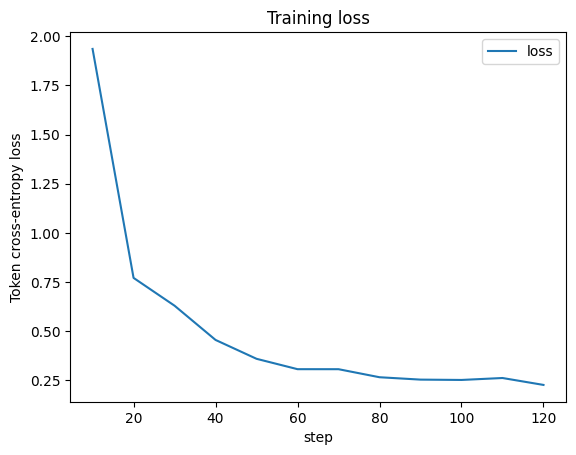

In [25]:
rows = []
if baseline_summary is not None:
    rows.append(baseline_summary)
if trained_summary is not None:
    rows.append(trained_summary)
if rows:
    display(pd.DataFrame(rows))
    existing_csv = output_root / "experiment_results.csv"
    old = pd.read_csv(existing_csv) if existing_csv.exists() else pd.DataFrame()
    updated = pd.concat([old, pd.DataFrame(rows)], ignore_index=True)
    updated = updated.drop_duplicates(subset=["experiment", "phase", "split"], keep="last")
    updated.to_csv(existing_csv, index=False)
    print("Results saved:", existing_csv)

if trainer is not None:
    history = pd.DataFrame(trainer.state.log_history)
    if "loss" in history:
        ax = history.dropna(subset=["loss"]).plot(x="step", y="loss", title="Training loss")
        ax.set_ylabel("Token cross-entropy loss")
        plt.show()

## 13. Try a new product

This is **text-only inference**, not web scraping. Paste an actual product title and description. Category is inferred by the model, not supplied.

In [29]:
new_product = {
    "input_title": "Samsung 990 PRO 2TB NVMe SSD",
    "input_description": "PCIe 4.0 M.2 internal solid state drive, 2 TB capacity",
}
print(generate_output(new_product))

{"attributes": {"Cache": null, "Capacity": "2000 Gigabytes", "Generation": null, "Interface": "PCIe 4.0", "Manufacturer": "Samsung", "Part Number": null, "Ports": null, "Processor Core": null, "Processor Type": null, "Product Type": "Storage Solutions", "Rotational Speed": null}, "category": "Computers And Accessories"}


## 14. Final held-out test (run once, after model selection)

The test split should not guide model choices or hyperparameters. When ready, load the **chosen** model/checkpoint and set `FINAL_TEST = True`. This cell evaluates the **entire** test split, not the short validation sample.

In [28]:
if FINAL_TEST:
    assert RUN_TRAINING or LOAD_CHECKPOINT_DIR, (
        "Load or train your chosen model before running the final test."
    )
    test_records = list(data["test"])
    final_summary, final_by_class, _ = evaluate_records(
        test_records, "final", "test"
    )
    display(pd.DataFrame([final_summary]))
    print("Category accuracy by class:", final_by_class)
    (run_dir / "final_test_metrics.json").write_text(
        json.dumps({"summary": final_summary, "by_class": final_by_class}, indent=2)
    )
else:
    print("Final test locked. Leave FINAL_TEST = False during experimentation.")

Final test locked. Leave FINAL_TEST = False during experimentation.


### Experiment ideas (one variable at a time)

Compare pretrained vs fine-tuned **Qwen3-1.7B** first. Next vary LoRA rank or learning rate; try **QLoRA** with the same Qwen model; then compare **SmolLM2-1.7B-Instruct** and **FLAN-T5-base**. For FLAN-T5, full fine-tuning is feasible on a decent Colab GPU. Record exact settings and avoid choosing a winner based on a few examples.

**References:** [WDC-PAVE](https://huggingface.co/datasets/siavashsaki/wdc-pave-ave), [Qwen3](https://huggingface.co/Qwen/Qwen3-1.7B), [SmolLM2](https://huggingface.co/HuggingFaceTB/SmolLM2-1.7B-Instruct), [FLAN-T5](https://huggingface.co/google/flan-t5-base), [PEFT](https://huggingface.co/docs/peft/index).

# Export for comparision

In [30]:

# Export experiment data for future comparisons.
import json
import re
import shutil
from importlib.metadata import PackageNotFoundError, version

comparison_dir = run_dir / "comparison_data"
prediction_dir = comparison_dir / "predictions"
prediction_dir.mkdir(parents=True, exist_ok=True)

# 1. Save experiment configuration.
config = {
    "experiment": EXPERIMENT_NAME,
    "model": MODEL_NAME,
    "model_id": MODEL_ID,
    "method": METHOD,
    "dataset": "siavashsaki/wdc-pave-ave",
    "dataset_sizes": {split: len(records) for split, records in data.items()},
    "training": {
        "seed": SEED,
        "epochs": EPOCHS,
        "learning_rate": LEARNING_RATE,
        "batch_size": BATCH_SIZE,
        "grad_accum_steps": GRAD_ACCUM_STEPS,
        "optimizer": OPTIMIZER,
        "lora_r": LORA_R,
        "lora_alpha": LORA_ALPHA,
        "lora_dropout": LORA_DROPOUT,
        "lora_target_modules": (
            ["q", "v"] if IS_SEQ2SEQ else ["q_proj", "v_proj"]
        ),
        "training_shots": 0,
    },
    "inference": {
        "evaluation_shots": N_SHOTS,
        "quick_eval_n": EVAL_N,
        "max_source_tokens": MAX_SOURCE_TOKENS,
        "max_target_tokens": MAX_TARGET_TOKENS,
        "do_sample": False,
        "num_beams": 1,
    },
    "system_prompt": SYSTEM_PROMPT,
    "category_schemas": CATEGORY_SCHEMAS,
    "few_shot_titles": FEW_SHOT_TITLES,
    "packages": {},
}

for name in ("torch", "transformers", "datasets", "peft", "accelerate"):
    try:
        config["packages"][name] = version(name)
    except PackageNotFoundError:
        pass

(comparison_dir / "config.json").write_text(
    json.dumps(config, indent=2, ensure_ascii=False),
    encoding="utf-8",
)

# 2. Recover previously recorded evaluation timing and VRAM.
known = {}
old_csv = output_root / "experiment_results.csv"

if old_csv.exists():
    for row in pd.read_csv(old_csv).to_dict("records"):
        if row.get("experiment") == EXPERIMENT_NAME:
            known[(row["phase"], row["split"], int(row["n"]))] = row

for name in (
    "baseline_summary", "trained_summary",
    "base_summary", "tuned_summary", "final_summary"
):
    summary = globals().get(name)
    if isinstance(summary, dict):
        key = (summary["phase"], summary["split"], int(summary["n"]))
        known[key] = summary

# 3. Recalculate metrics from every saved prediction file.
evaluations = []

for path in sorted(run_dir.glob("*_predictions.jsonl")):
    phase, split = path.name.removesuffix(
        "_predictions.jsonl"
    ).rsplit("_", 1)

    saved = [
        json.loads(line)
        for line in path.read_text(encoding="utf-8").splitlines()
        if line.strip()
    ]

    records = []
    outputs = []

    for item in saved:
        gold = json.loads(item["gold"])
        records.append({
            "category": gold["category"],
            "gold_json": gold["attributes"],
        })
        outputs.append(item["prediction"])

    scores = score_predictions(records, outputs)
    per_category = scores.pop("category_accuracy_by_class")

    metrics = {
        **known.get((phase, split, len(records)), {}),
        "experiment": EXPERIMENT_NAME,
        "model": MODEL_NAME,
        "method": METHOD,
        "phase": phase,
        "split": split,
        "n": len(records),
        **scores,
    }

    match = re.search(r"(\d+)shot", phase)
    metrics["prompt_shots"] = (
        int(match.group(1)) if match else
        0 if phase == "schema_zero_shot" else
        N_SHOTS if phase in {"fine_tuned", "final"} else None
    )

    evaluations.append({
        "metrics": metrics,
        "category_accuracy_by_class": per_category,
    })

    shutil.copy2(path, prediction_dir / path.name)

assert evaluations, f"No prediction files found in {run_dir}"

(comparison_dir / "metrics.json").write_text(
    json.dumps(evaluations, indent=2, ensure_ascii=False),
    encoding="utf-8",
)

pd.DataFrame(
    [item["metrics"] for item in evaluations]
).to_csv(comparison_dir / "metrics.csv", index=False)

# 4. Save training history, including loss across steps.
current_trainer = globals().get("trainer")

if current_trainer is not None:
    history = current_trainer.state.log_history
else:
    states = sorted(
        (run_dir / "checkpoints").glob(
            "checkpoint-*/trainer_state.json"
        )
    )
    history = (
        json.loads(states[-1].read_text())["log_history"]
        if states else []
    )

if history:
    pd.DataFrame(history).to_csv(
        comparison_dir / "training_history.csv",
        index=False,
    )

print(f"Exported {len(evaluations)} evaluation sets.")
print("Saved to:", comparison_dir)
print("Files:", [p.name for p in sorted(comparison_dir.iterdir())])


Exported 6 evaluation sets.
Saved to: /content/drive/MyDrive/WDC-PAV-Finetuning/qwen3-lora-01/comparison_data
Files: ['config.json', 'metrics.csv', 'metrics.json', 'predictions', 'training_history.csv']
